   ...
THE PROBLEM ACT SOLVES: You have a few dozen human demonstrations of a task. You
   want a policy that copies them. Copying one action at a time fails for two
   reasons. Small errors change the next observation and the errors grow. Humans
   also do the same thing in different ways and averaging those ways gives a 
   motion nobody did.

THE IDEA. Predict a chunk of k future actions froom one observation instead of
   one action. At 50 Hz a chunk of k = 100 is two seconds of motion. The policy
   now makes a decision every two seconds instead of every 20 ms. Errors 
   compound fifty times less often. Each chunk commits to one way of doing the 
   motion so modes are no averaged inside a chunk.


-- A single step policy chooses an action every 20 ms. It might choose `left` at
   one step and `right` at the next. Then the arm moves back and forth and moves
   back and forth between the two modes.

   A chunk is one output covering 100 steps. It is trained using complete 
   demonstration sequences. Therefore, the motion within one chunk follows one
   consistent path. It cannot switch between modes halfway through.

   However, the sentence is only partly true. A chunk by itself does not choose 
   a mode. An L1 or L2 regressor for a complete chunk can still produce an
   average of the left path and the right path. 

   THe CVAE latent z chooses the mode. It tells the decodeer which mode the
   training target came from. 

-- In ACT, the CVAE latent z is a 32 dimensional vector known as the "style
   variable".

   Its purpose is to capture and parameterize the high-level human variability--
   such as differences in speed, trajectory, approach angle, or grasp 
   orientation--present across multiple demonstrations of the same robotic task.

   - PHASE: Training
   - WHAT Z DOES: Captures demonstration style... CVAE encoder reviews the 
     upcoming target action chunk along with the robot's current state. It 
     compresses this sequence into a distribution (\mu and \sigma), from which
     z is sampled, 



---


-- A mode is one valid way to do the same motion from the same state. In the
   clamp example, "pass left" is one mode and "pass right" is the other. 
   The action distribution has two peaks, with no valid action between
   them. "Modes are averaged" means the policy chooses the midpoints between
   these peaks. That midpoint means "go straight into the clamp, which no demonstrator ever did. 
   

-- A Conditional Variational Autoencoder generates sequences of actions by
   modelling possible future behaviours. It treats target

   A Conditional Variational Autoencoder maps the current robot state into a 
   latent space which multiple different, valid future trajectories can be 
   sampled. In environments with obstacles or humans, a single determinsitic
   path  might be blocked or suboptimal... so gernetating a distribution of
   options allows the robot to execute and pick the safest route. During
   inference, the latent variable $z$ is indeed sampled randomly from a 
   STD normal distribution, providing  the necessary variance to explore 
   different potential action chunks. WHile a robot cannot reversse time...
   generating and evaluating these multiple "what-if" paths internally before 
   execution prevents it from commiting a collision. This component is 
   essential because real-world robotics is inherently stochastic, and a model
   that only predicts one rigid sequence will inevitably fail when unexpected 
   dynamics occur. 

---

   A Variational Autoencoder (VAE) is a deep learning generative model that
   llearns a smoooth, probabilistic latent space. It combines an encoder and a 
   decoder: the encoder maps inputs into a mean and variance rather than a 
   fixed point, alowing the decoder to sample from this distribution and 
   generate new, realistic data.

   ... mental model describes a standard Autoencoder, which maps an input to a
   single, deterministc point in the latent space. The problem with this 
   deterministic approach is that it only learns specific isolated points, 
   leaving massive empty gaps in the latent space where the decoder has no
   meaningful data to draw from. If you were to randomly sample a vector from 
   one of those empty gaps, the decoder wouldwould simply output meaningless 
   noise...

   VAEs requires \u and \sigma to transform these isolated points into 
   continuous overlapping 

   ARCHITECTURE OF ACTIN CHUNKING WITH TRANSFORMERS (ACT)

   We train ACT as a Conditional VAE (CVAE), which has an encoder and a decoder.
   - LEFT: The encoder of the CVAE compresses action sequence and joint 
     observation into z, the style variable.

-- In a CVAE, the STYLE VARIABLE (or conditional variable, suually denoted as y)
   is an auxiliary input--such as a class label, attribute, or one-hot vector
   --fed into both the encoder and decoder to guide data generation. 

-- 

---


   Treating the CVAE as a CONTINUOUS, SOFT CLASSIFIER FOR TRAJECTORY STYLES is
   the perfect mental mdel, especially for operations like cable rack insertion
   where the distinct "classes" are simply the different spatial paths taken
   to align with the port. The `D_KL` regularizer that forces these trajectory
   classes to bleed into each other, ensuring the resulting latent space has
   no undefined gapss.... 

   Reprojection error is the distance between where a feature point appears in a
   2D image and whee a camera model predicts it should land based on its 
   estimated 3D position. It is measured in pixels and show how well a camera or
   scene model matches reality.

   VLA models fundamentally map raw camera pixels and text instructions
   directly into robotic control commands using massive transformer backbones.
   Because these models often contain billions of parameters, calculating a 
   single forward pass.... autoregressive decoding process... When a robotic
   system requires a control loop running at 50 Hz, meaning it needs a fresh
   joint command every 0.02 seconds, generating tokens one-by-one through a
   7-billion parameter netwrk is mathematically impossible... structural latency
   would force the physical hardware to sit idle while waiting for the next 
   coommand... resulting in catastrophic suttering or dangerous momentum shifts
   during dynamic physics interactiions. 

   To bridge this critical gap between slow transformer inference and fast
   physical dynamics, VLAs rely on action chunking to predict entire sequence
   blocks at once. Instead of outputting a single immediate joint configuration,
   the network decodes a bundled trajectory of future waypoints during that one
   computationally expensive forward pass.... while deterministic local 
   controllers handle the strict microsecond deadlines required for actual
   motor stability. By buffering these generated waypoints, the system 
   effectively hides the transformer's inherent latency behind a continuous, 
   smooth stream of execution.

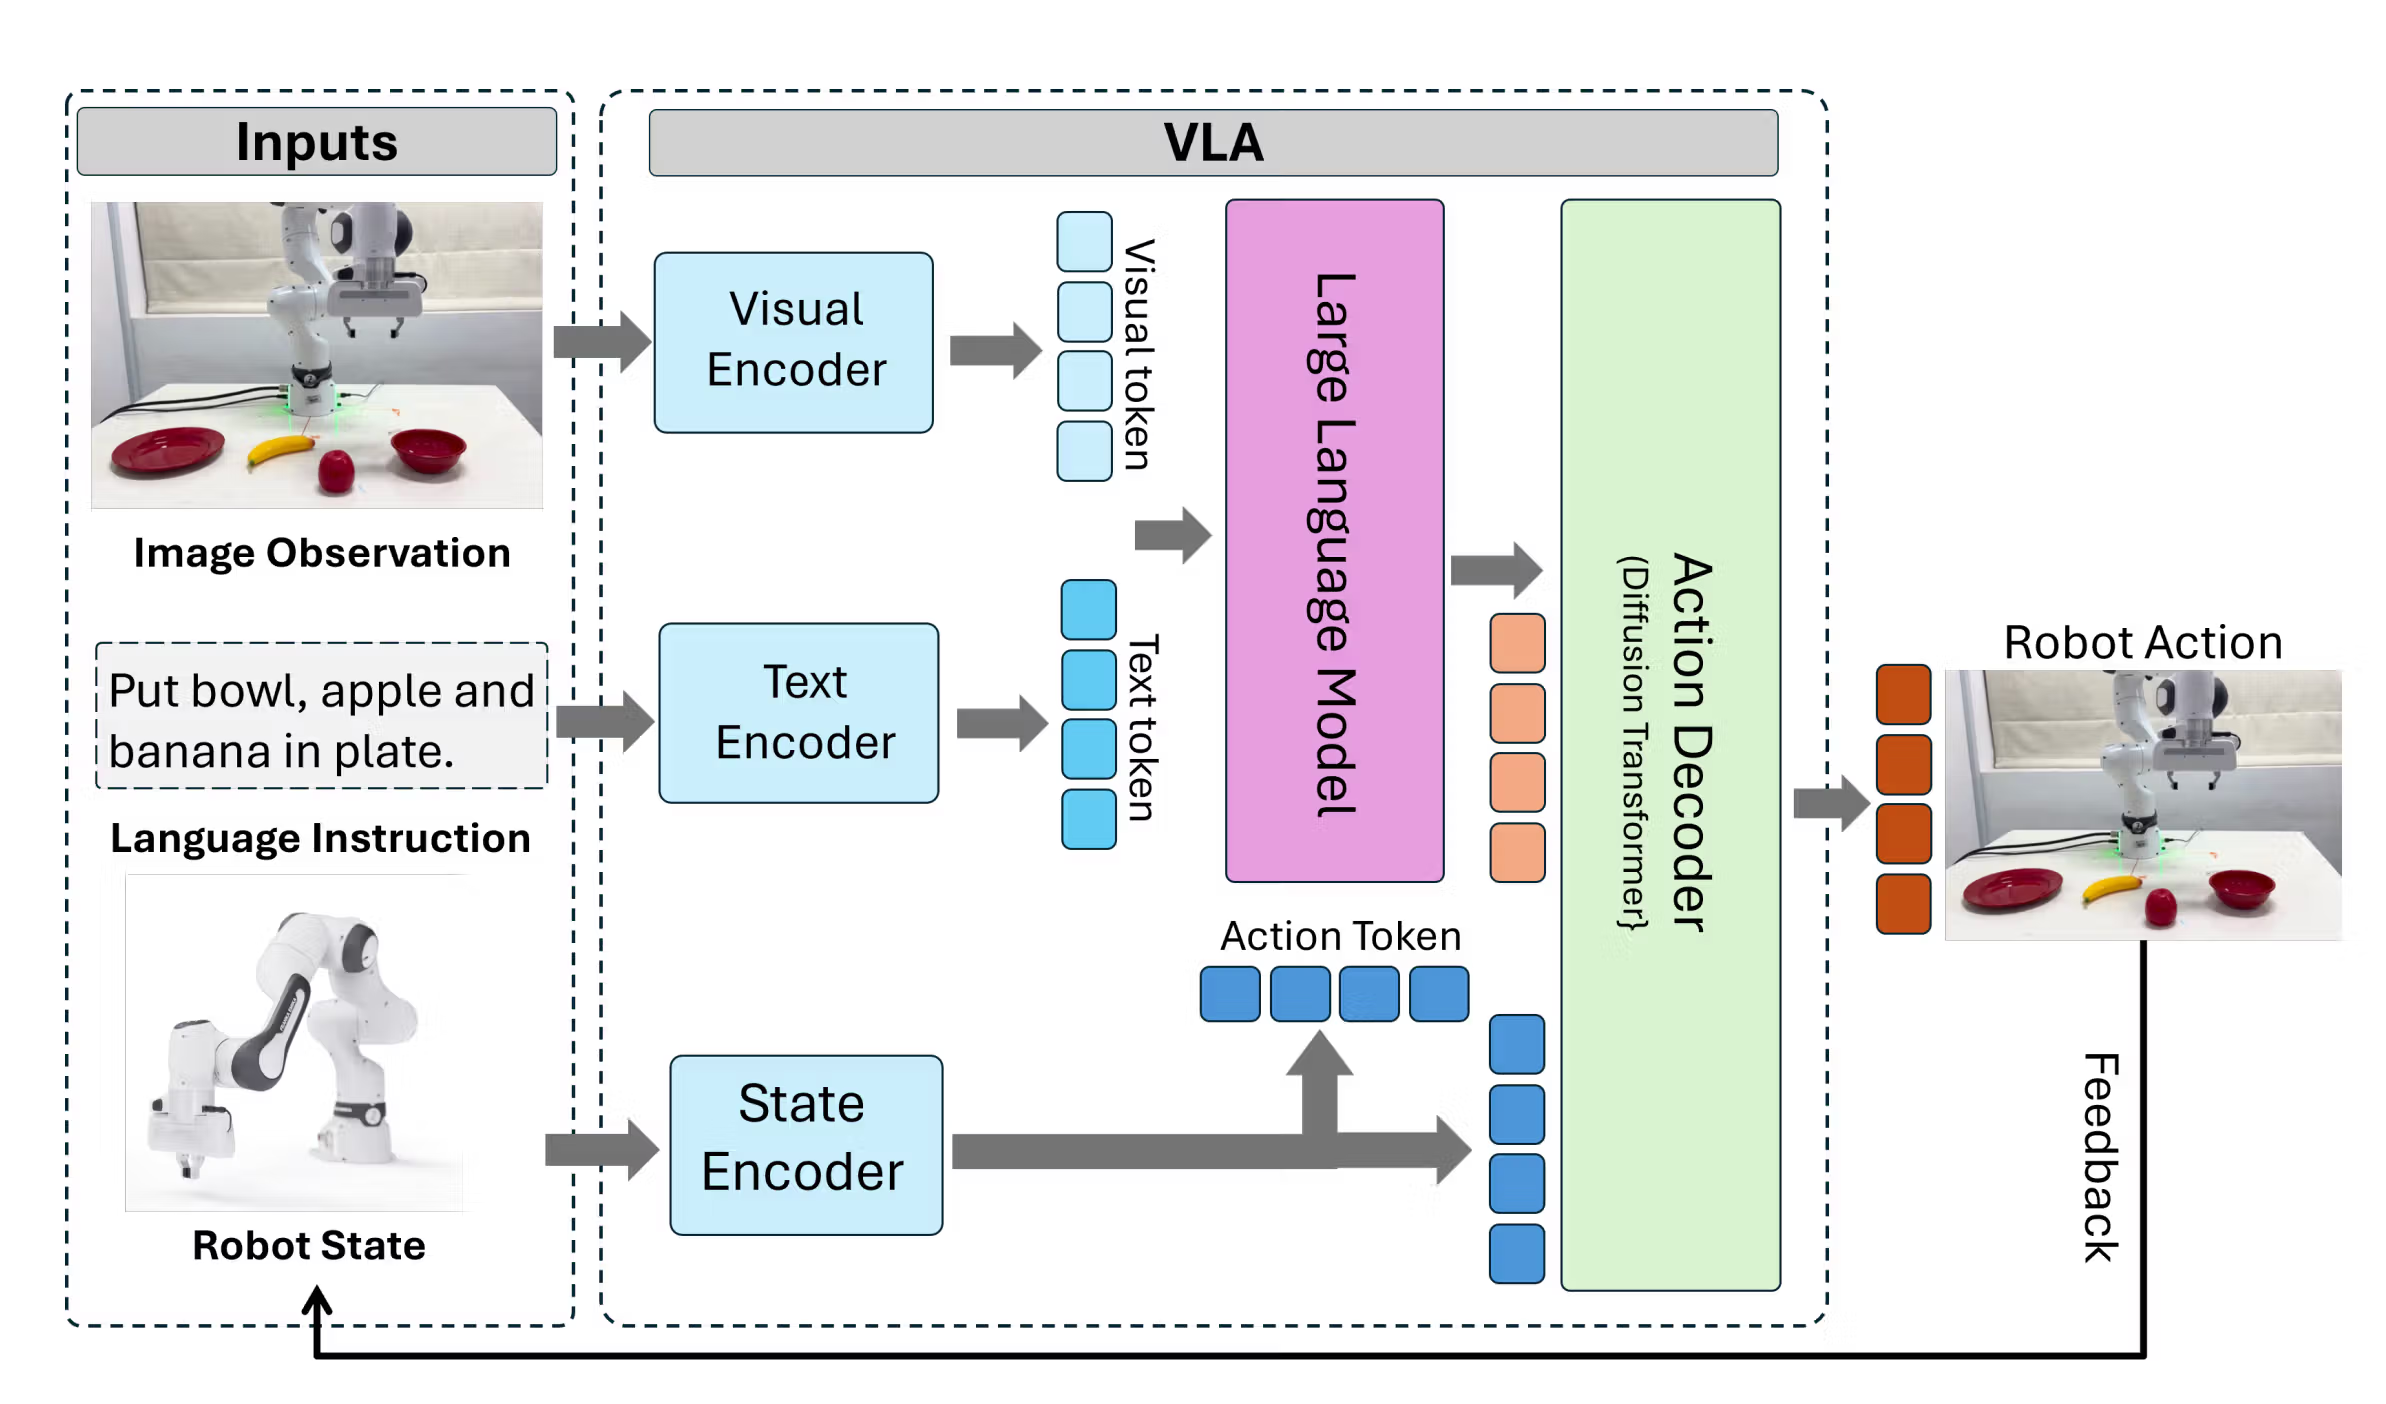

answer me in 1 paragraph, 5-6 sentences, and 1 comma each 

